# Assignment 6

Histogram equalization, then histogram matching.

Input: `sample_lena.png` (washed out, narrow histogram). Reference: `sample_portrait.jpg`.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# histogram equalization, then histogram matching
# matching uses the equalization transform of both images

def eq_levels(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    cdf = np.cumsum(hist)
    used = np.flatnonzero(hist)
    levels = np.zeros(256, dtype=np.float64)
    if used.size == 0:
        return levels
    cdf_min = cdf[used[0]]
    span = cdf[-1] - cdf_min
    if span <= 0:
        return levels
    # skip the empty bins at the bottom, then stretch the rest across 0-255
    levels = (cdf - cdf_min) * 255.0 / span
    levels[:used[0]] = 0
    return levels


def equalize(img):
    lut = np.clip(np.round(eq_levels(img)), 0, 255).astype(np.uint8)
    return lut[img]


def equalization_map(img):
    # s = (L - 1) * cdf
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    cdf = np.cumsum(hist)
    if cdf[-1] == 0:
        return np.zeros(256)
    return (cdf / cdf[-1]) * 255.0


def match_histogram(src, ref):
    s = equalization_map(src)   # equalize the input
    g = equalization_map(ref)   # equalize the reference
    lut = np.zeros(256, dtype=np.uint8)
    for r in range(256):
        # z whose equalized value is closest to s[r]
        z = int(np.argmin(np.abs(g - s[r])))
        lut[r] = z
    return lut[src]


def read_gray(path):
    img = cv2.imread(path, 0)
    if img is None:
        print("Image not found:", path)
        exit()
    return img


def show_hist(ax, img, title):
    ax.hist(img.ravel(), bins=256, range=(0, 256), color="dimgray")
    ax.set_title(title)
    ax.set_xlim(0, 255)


input: sample_lena.png (459, 466)
reference: sample_portrait.jpg (256, 256)
equalized image mean 129.12  original mean 136.98
equalized std 73.63  original std 24.99
matched mean 136.07  reference mean 135.1
matched std 61.13  reference std 61.5


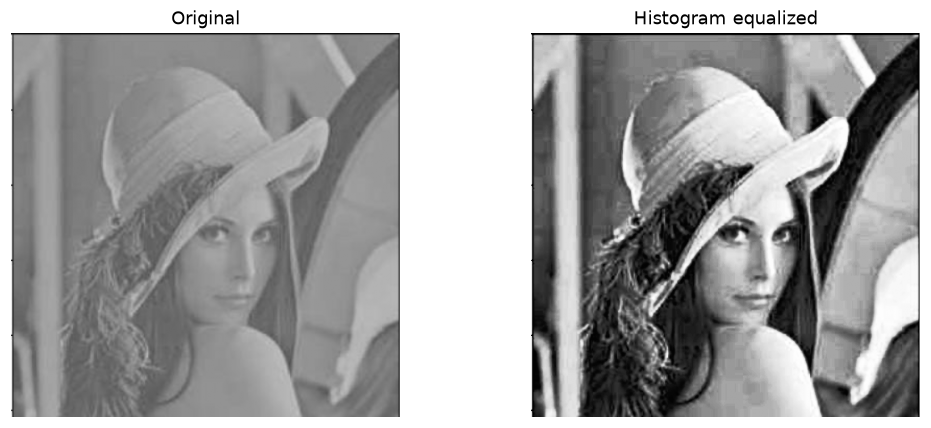

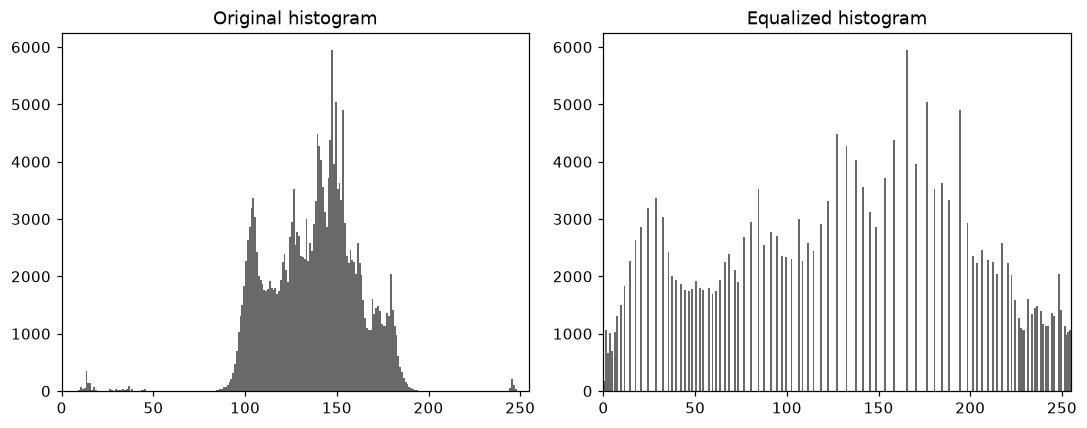

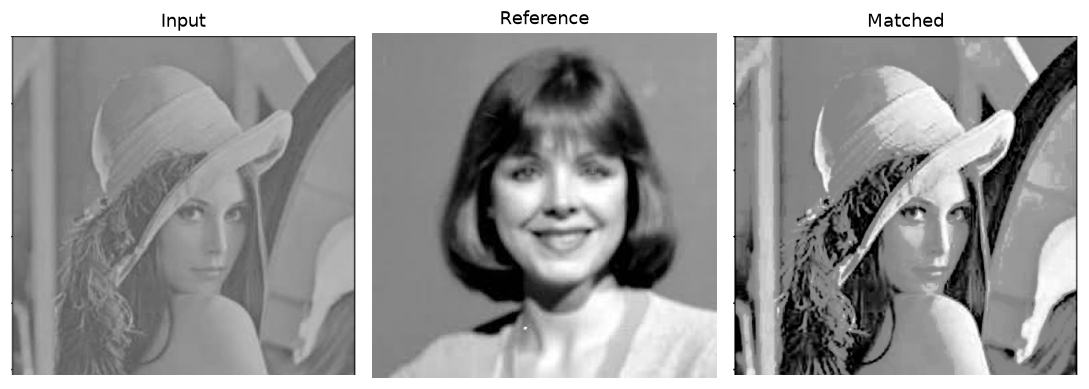

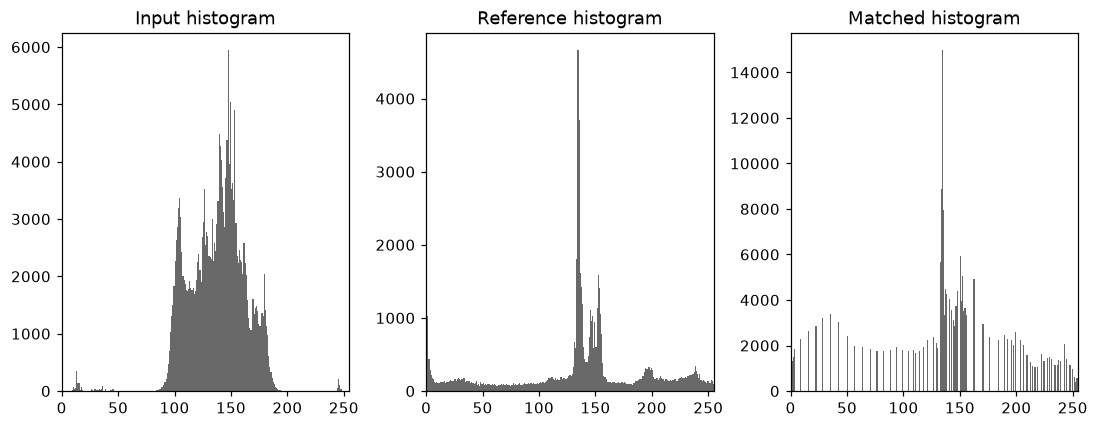

In [2]:
image_path = "sample_lena.png"
ref_path = "sample_portrait.jpg"

img = read_gray(image_path)
ref = read_gray(ref_path)
print("input:", image_path, img.shape)
print("reference:", ref_path, ref.shape)

eq = equalize(img)
matched = match_histogram(img, ref)

print("equalized image mean", round(float(eq.mean()), 2), " original mean", round(float(img.mean()), 2))
print("equalized std", round(float(eq.std()), 2), " original std", round(float(img.std()), 2))
print("matched mean", round(float(matched.mean()), 2), " reference mean", round(float(ref.mean()), 2))
print("matched std", round(float(matched.std()), 2), " reference std", round(float(ref.std()), 2))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(eq, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram equalized")
plt.axis("off")
plt.tight_layout()

plt.figure(figsize=(10, 4))
show_hist(plt.subplot(1, 2, 1), img, "Original histogram")
show_hist(plt.subplot(1, 2, 2), eq, "Equalized histogram")
plt.tight_layout()

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Input")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(ref, cmap="gray", vmin=0, vmax=255)
plt.title("Reference")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(matched, cmap="gray", vmin=0, vmax=255)
plt.title("Matched")
plt.axis("off")
plt.tight_layout()

plt.figure(figsize=(10, 4))
show_hist(plt.subplot(1, 3, 1), img, "Input histogram")
show_hist(plt.subplot(1, 3, 2), ref, "Reference histogram")
show_hist(plt.subplot(1, 3, 3), matched, "Matched histogram")
plt.tight_layout()
plt.show()
